# 🪐 Exoplanet Transit Analysis Using TESS
### Photometric analysis and transit characterization of known exoplanets

**Goal:** Download public TESS light curves of three known transiting hot Jupiters, clean and normalize them, find the transit dips, fold on the orbital period, and use the transit depth to estimate the planet-to-star radius ratio. We then compare our results with published values.

**Targets**

| Planet | Why it is a good target |
|---|---|
| WASP-18 b | Very short period (~0.94 d), many transits per sector |
| HD 209458 b | The first transiting exoplanet ever found, a bright star with a clean signal |
| WASP-121 b | Ultra-hot Jupiter (~1.27 d), a deep transit |

**Pipeline (for each star)**

1. Download TESS SPOC 2-minute light curves (MAST) via `lightkurve`
2. Remove NaNs and outliers
3. Normalize the flux
4. Detrend stellar/instrumental variability (transits masked so they aren't removed)
5. Find the transit dips blindly with a Box Least Squares (BLS) periodogram
6. Fold on the period and plot the phase-folded transit
7. Measure the transit depth, derive Rp/R★, and compare with the NASA Exoplanet Archive

## 1. Imports and settings

In [8]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from astropy import units as u
import lightkurve as lk

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.labelsize": 11, "axes.titlesize": 12, "legend.fontsize": 9,
})
print("lightkurve version:", lk.__version__)

lightkurve version: 2.6.0


## 2. Target list and published values

The reference values below are the approximate published values (as listed in the **NASA Exoplanet Archive** "Planetary Systems" table). They are used **only for comparison**, not as inputs to the BLS detection. Please double-check them against the archive: https://exoplanetarchive.ipac.caltech.edu

* `period` is the orbital period in days
* `rp_rs` is the published planet-to-star radius ratio
* `flatten_days` is the detrending window. It must be several times longer than the transit duration (~2–3 h) so the filter doesn't eat the transit.

In [9]:
TARGETS = {
    "WASP-18 b": dict(
        search="WASP-18",      period=0.94145223, rp_rs=0.0975, flatten_days=0.75, n_sectors=2),
    "HD 209458 b": dict(
        search="HD 209458",    period=3.52474859, rp_rs=0.1207, flatten_days=1.00, n_sectors=2),
    "WASP-121 b": dict(
        search="WASP-121",     period=1.27492504, rp_rs=0.1218, flatten_days=0.75, n_sectors=2),
}

## 3. Helper functions

Short, reusable functions so that the main analysis loop stays readable.

In [10]:
def _val(x):
    """Return a plain float from an astropy Quantity/Time (or a float)."""
    return float(x.value) if hasattr(x, "value") else float(x)


def download_lightcurves(search_name, n_sectors=2):
    """Download PDCSAP 2-min SPOC light curves for the first n_sectors available sectors."""
    sr = lk.search_lightcurve(search_name, mission="TESS", author="SPOC", exptime=120)
    if len(sr) == 0:
        raise RuntimeError(f"No 2-min SPOC TESS light curves found for {search_name}")
    sr = sr[:n_sectors]
    print(sr.table["mission", "year", "exptime"] if hasattr(sr, "table") else sr)
    return sr.download_all(flux_column="pdcsap_flux")


def clean_lightcurve(lc, sigma_upper=4, sigma_lower=20):
    """Remove NaNs and outliers, then normalize.

    Clipping is *asymmetric*: we clip strongly on the upper side (cosmic rays,
    flares) but are very permissive on the lower side, so that real transit dips
    are NOT removed as 'outliers'.
    """
    lc = lc.remove_nans()
    lc = lc.remove_outliers(sigma_upper=sigma_upper, sigma_lower=sigma_lower)
    return lc.normalize()


def flatten_days(lc, window_days, mask=None):
    """Remove slow trends with a Savitzky-Golay filter of length ~window_days."""
    cadence = np.nanmedian(np.diff(lc.time.value))          # days per cadence
    n = int(window_days / cadence)
    n += (n % 2 == 0)                                        # window must be odd
    return lc.flatten(window_length=n, polyorder=2, break_tolerance=10, mask=mask)


def run_bls(lc, p_min=0.5, p_max=10.0):
    """Blind Box-Least-Squares search: a coarse grid, then a fine grid around the peak."""
    durations = [0.04, 0.06, 0.08, 0.10, 0.14]               # days
    coarse = lc.to_periodogram("bls", period=np.linspace(p_min, p_max, 30000), duration=durations)
    p0 = _val(coarse.period_at_max_power)
    fine = lc.to_periodogram("bls", period=np.linspace(p0 - 0.01, p0 + 0.01, 4000), duration=durations)
    return coarse, fine


def trapezoid(t, depth, t14, t12, t0):
    """Symmetric trapezoid: depth, total duration T14, ingress/egress time T12, mid-time t0."""
    x = np.abs(t - t0)
    half = t14 / 2.0
    model = np.ones_like(t)
    flat = x <= (half - t12)
    ingress = (x > (half - t12)) & (x < half)
    model[flat] = 1 - depth
    model[ingress] = 1 - depth * (half - x[ingress]) / t12
    return model


def bin_phase(x, y, width):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    """Simple fixed-width binning, returns bin centres, means and standard errors."""
    edges = np.arange(x.min(), x.max() + width, width)
    idx = np.digitize(x, edges)
    xb, yb, eb = [], [], []
    for i in np.unique(idx):
        sel = idx == i
        if sel.sum() >= 5:
            xb.append(x[sel].mean()); yb.append(y[sel].mean())
            eb.append(y[sel].std() / np.sqrt(sel.sum()))
    return np.array(xb), np.array(yb), np.array(eb)

## 4. Main analysis function

For one target this function runs the full pipeline and makes four figures:

1. Raw vs. cleaned and detrended light curve (with the transits marked)
2. BLS periodogram
3. Phase-folded light curve
4. Zoom on the transit with the trapezoid fit

**How the depth is measured (two independent ways):**

* **Direct:** median flux in the flat bottom of the transit vs. the out-of-transit baseline.
* **Model:** a trapezoid fit with `scipy.optimize.curve_fit`.

For a star with uniform brightness, depth = (Rp/R★)². So Rp/R★ ≈ √depth.

In [11]:
def analyze_target(name, cfg):
    print("=" * 70, f"\n{name}\n" + "=" * 70)
    P_pub, k_pub = cfg["period"], cfg["rp_rs"]

    lcc = download_lightcurves(cfg["search"], cfg["n_sectors"])
    raw = lcc.stitch()                      # stitch sectors (each normalized)
    n_raw = len(raw)

    lc = clean_lightcurve(raw)
    print(f"Cadences: raw={n_raw}, after cleaning={len(lc)}")

    flat1 = flatten_days(lc, cfg["flatten_days"])
    coarse, fine = run_bls(flat1)
    P_bls = _val(fine.period_at_max_power)
    t0    = _val(fine.transit_time_at_max_power)
    dur   = _val(fine.duration_at_max_power)
    depth_bls = _val(fine.depth_at_max_power)
    print(f"BLS: P = {P_bls:.5f} d | T0 = {t0:.4f} BTJD | duration = {dur*24:.2f} h | depth = {depth_bls*100:.3f} %")

    # (masking prevents the filter from partially fitting out the transit)
    mask = lc.create_transit_mask(period=P_bls, transit_time=t0, duration=dur * 3)
    flat = flatten_days(lc, cfg["flatten_days"], mask=mask)
    flat = flat.remove_outliers(sigma_upper=4, sigma_lower=20)

    fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
    ax[0].plot(raw.time.value, raw.flux.value, ".", ms=1, color="0.6", label="raw (PDCSAP, normalized)")
    ax[0].plot(lc.time.value,  lc.flux.value,  ".", ms=1, color="C0", label="cleaned")
    ax[0].set_ylabel("Norm. flux"); ax[0].legend(markerscale=6, loc="lower right")
    ax[0].set_title(f"{name}: TESS light curve")
    ax[1].plot(flat.time.value, flat.flux.value, ".", ms=1, color="k", label="detrended")
    n_start = int(np.floor((flat.time.value.min() - t0) / P_bls))
    n_end   = int(np.ceil((flat.time.value.max() - t0) / P_bls))
    for n in range(n_start, n_end + 1):
        tc = t0 + n * P_bls
        if flat.time.value.min() <= tc <= flat.time.value.max():
            ax[1].axvline(tc, color="r", alpha=0.25, lw=1)
    ax[1].set_ylabel("Norm. flux"); ax[1].set_xlabel("Time [BTJD]")
    ax[1].legend(markerscale=6, loc="lower right")
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(12, 3.2))
    ax.plot(coarse.period.value, coarse.power.value, lw=0.7)
    ax.axvline(P_pub, color="r", ls="--", alpha=0.7, label=f"published P = {P_pub:.5f} d")
    ax.set_xlabel("Period [d]"); ax.set_ylabel("BLS power")
    ax.set_title(f"{name}: BLS periodogram"); ax.legend()
    plt.tight_layout(); plt.show()

    folded = flat.fold(period=P_bls, epoch_time=t0)
    # convert possibly-masked arrays to plain float arrays and drop non-finite points
    ph = np.ma.filled(np.ma.asarray(folded.time.value, dtype=float), np.nan)   # days from mid-transit
    fl = np.ma.filled(np.ma.asarray(folded.flux.value, dtype=float), np.nan)
    good = np.isfinite(ph) & np.isfinite(fl)
    ph, fl = ph[good], fl[good]
    ph_h = ph * 24                           # in hours for nicer axes

    t14_guess = dur
    in_flat = np.abs(ph) < 0.25 * t14_guess             # flat bottom of transit
    out_tr  = np.abs(ph) > 1.0 * t14_guess              # clearly out of transit
    base = np.median(fl[out_tr])
    depth_direct = float(base - np.median(fl[in_flat]))
    depth_err = np.sqrt(np.std(fl[in_flat])**2 / in_flat.sum() +
                        np.std(fl[out_tr])**2 / out_tr.sum())

    p0 = [depth_direct, t14_guess, 0.15 * t14_guess, 0.0]
    bounds = ([0, 0.5 * t14_guess, 1e-3, -0.05], [0.1, 2.0 * t14_guess, t14_guess / 2, 0.05])
    sel = np.abs(ph) < 3 * t14_guess
    popt, pcov = curve_fit(trapezoid, ph[sel], fl[sel], p0=p0, bounds=bounds)
    perr = np.sqrt(np.diag(pcov))
    depth_fit, t14_fit = popt[0], popt[1]

    k_direct = np.sqrt(depth_direct)
    k_fit    = np.sqrt(depth_fit)
    k_err    = 0.5 * perr[0] / k_fit                    # error propagation: dk = d(depth) / (2k)

    xb, yb, eb = bin_phase(ph_h, fl, width=10 / 60)     # 10-minute bins
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    ax[0].plot(ph / P_bls, fl, ".", ms=1, color="0.7")
    ax[0].set_xlabel("Phase"); ax[0].set_ylabel("Norm. flux")
    ax[0].set_title(f"{name}: full phase-folded curve")
    ax[0].set_ylim(1 - 2.5 * depth_fit, 1 + 0.6 * depth_fit)

    win = 3 * t14_guess * 24
    m = np.abs(ph_h) < win
    tt = np.linspace(-win, win, 1000)
    ax[1].plot(ph_h[m], fl[m], ".", ms=2, color="0.75", label="TESS 2-min")
    ax[1].errorbar(xb[np.abs(xb) < win], yb[np.abs(xb) < win], eb[np.abs(xb) < win],
                   fmt="o", ms=4, color="k", label="10-min bins")
    ax[1].plot(tt, trapezoid(tt / 24, *popt), "r-", lw=2, label=f"trapezoid fit (depth {depth_fit*100:.2f} %)")
    ax[1].axhline(1 - depth_direct, color="C0", ls=":", label=f"direct depth {depth_direct*100:.2f} %")
    ax[1].set_xlabel("Hours from mid-transit"); ax[1].set_ylabel("Norm. flux")
    ax[1].set_title(f"{name}: transit zoom"); ax[1].legend(loc="lower right")
    plt.tight_layout(); plt.show()

    n_tr = len({int(np.round((t - t0) / P_bls)) for t in flat.time.value[np.abs(((flat.time.value - t0 + P_bls/2) % P_bls) - P_bls/2) < dur/2]})
    result = {
        "Planet": name,
        "Sectors": cfg["n_sectors"],
        "Transits seen": n_tr,
        "P_BLS [d]": round(P_bls, 5),
        "P_published [d]": P_pub,
        "ΔP [s]": round((P_bls - P_pub) * 86400, 1),
        "T14 [h]": round(t14_fit * 24, 2),
        "Depth direct [%]": round(depth_direct * 100, 3),
        "Depth fit [%]": round(depth_fit * 100, 3),
        "Rp/R* (fit)": round(k_fit, 4),
        "Rp/R* (±)": round(k_err, 4),
        "Rp/R* (published)": k_pub,
        "Diff [%]": round(100 * (k_fit - k_pub) / k_pub, 1),
    }
    print(pd.Series(result).to_string())
    return result, (xb, yb, eb, popt)

## 5. Run the analysis

This downloads data from MAST, so the first run takes a few minutes.

WASP-18 b
   mission     year exptime
                       s   
-------------- ---- -------
TESS Sector 02 2018     120
TESS Sector 03 2018     120


Cadences: raw=31840, after cleaning=31163
BLS: P = 0.94142 d | T0 = 1354.4595 BTJD | duration = 1.92 h | depth = 0.990 %


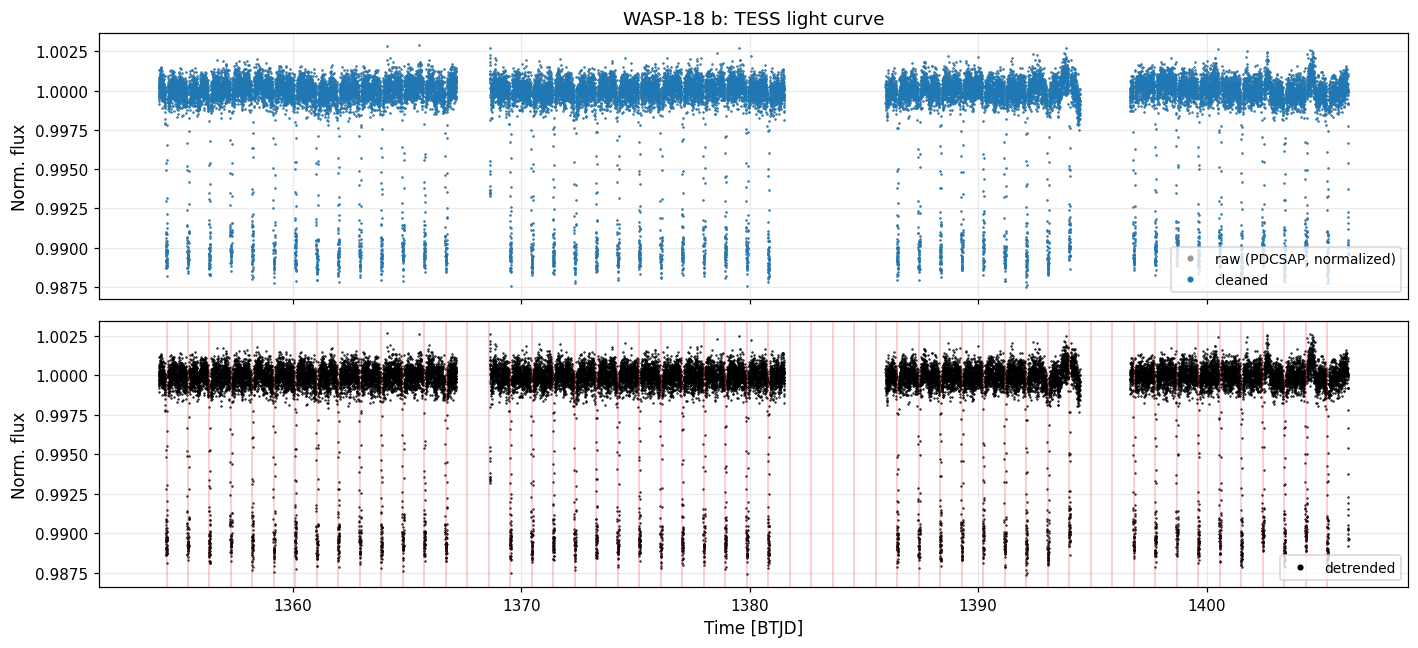

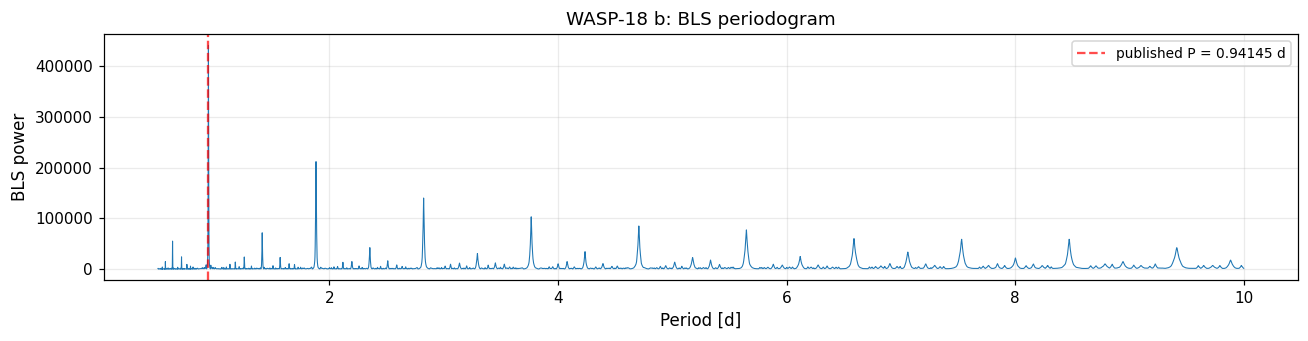

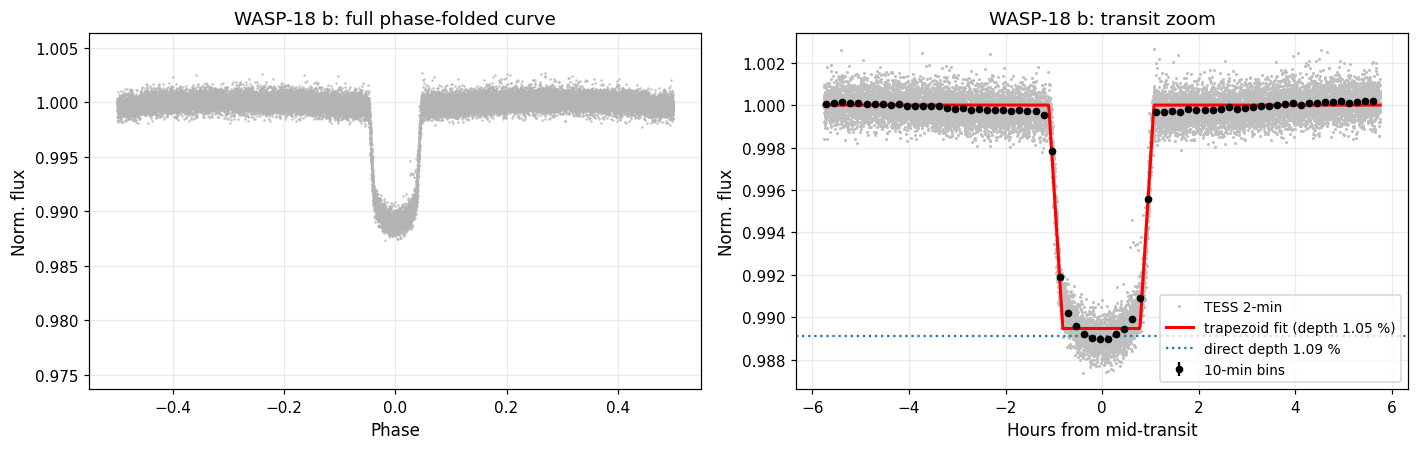

Planet               WASP-18 b
Sectors                      2
Transits seen               48
P_BLS [d]              0.94142
P_published [d]       0.941452
ΔP [s]                    -3.2
T14 [h]                   2.18
Depth direct [%]          1.09
Depth fit [%]            1.053
Rp/R* (fit)             0.1026
Rp/R* (±)               0.0001
Rp/R* (published)       0.0975
Diff [%]                   5.3
HD 209458 b
   mission     year exptime
                       s   
-------------- ---- -------
TESS Sector 56 2022     120
TESS Sector 82 2024     120
Cadences: raw=37568, after cleaning=35776


`period` contains 2559008 points.Periodogram is likely to be large, and slow to evaluate. Consider setting `frequency_factor` to a higher value.


BLS: P = 3.52475 d | T0 = 2826.7806 BTJD | duration = 2.40 h | depth = 1.494 %


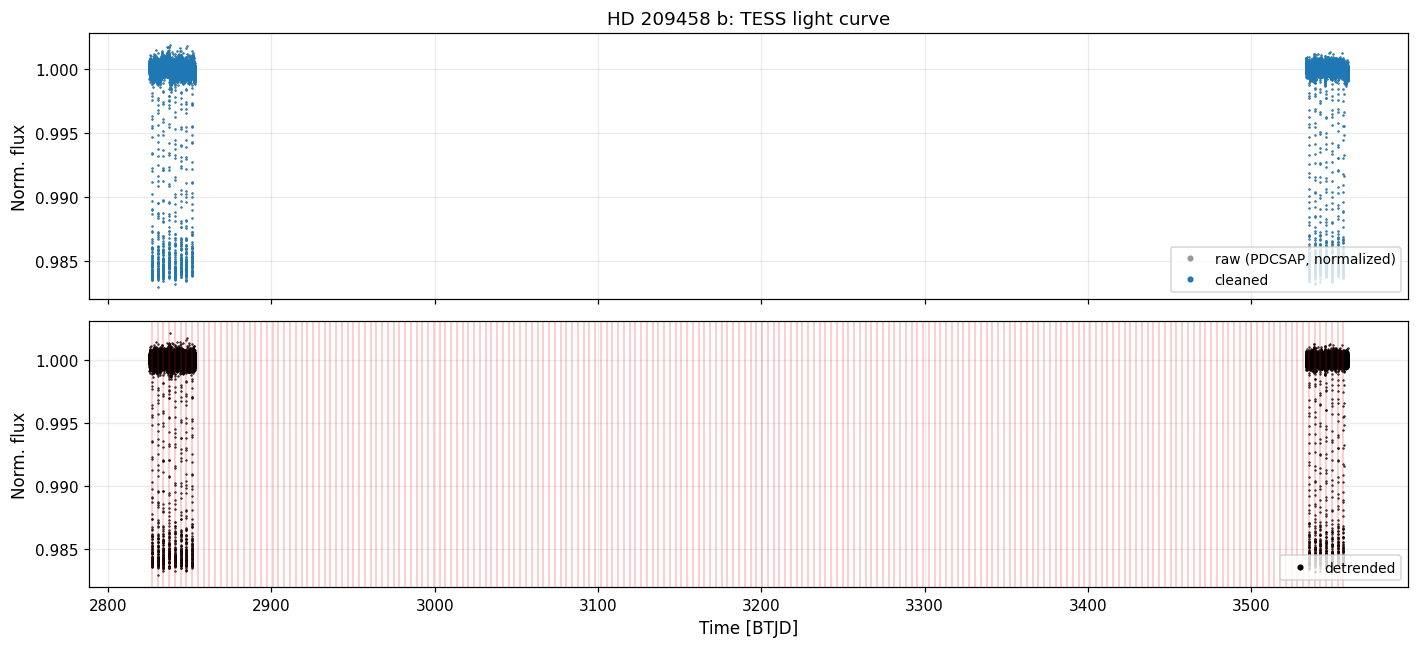

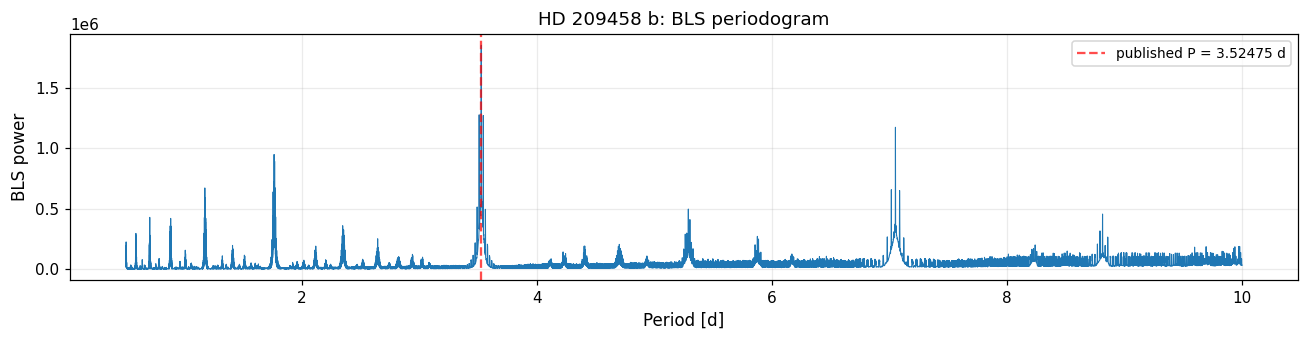

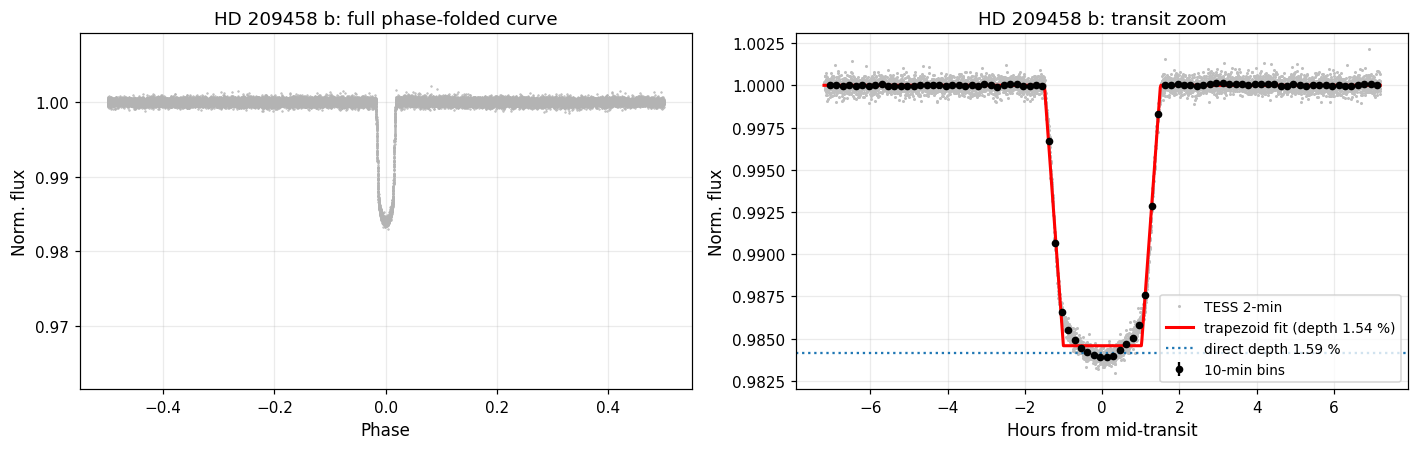

Planet               HD 209458 b
Sectors                        2
Transits seen                 15
P_BLS [d]                3.52475
P_published [d]         3.524749
ΔP [s]                      -0.0
T14 [h]                      3.0
Depth direct [%]           1.587
Depth fit [%]              1.542
Rp/R* (fit)               0.1242
Rp/R* (±)                 0.0001
Rp/R* (published)         0.1207
Diff [%]                     2.9
WASP-121 b
   mission     year exptime
                       s   
-------------- ---- -------
TESS Sector 07 2019     120
TESS Sector 33 2020     120
Cadences: raw=33797, after cleaning=33797


`period` contains 2572636 points.Periodogram is likely to be large, and slow to evaluate. Consider setting `frequency_factor` to a higher value.


BLS: P = 1.27492 d | T0 = 1492.0005 BTJD | duration = 2.40 h | depth = 1.449 %


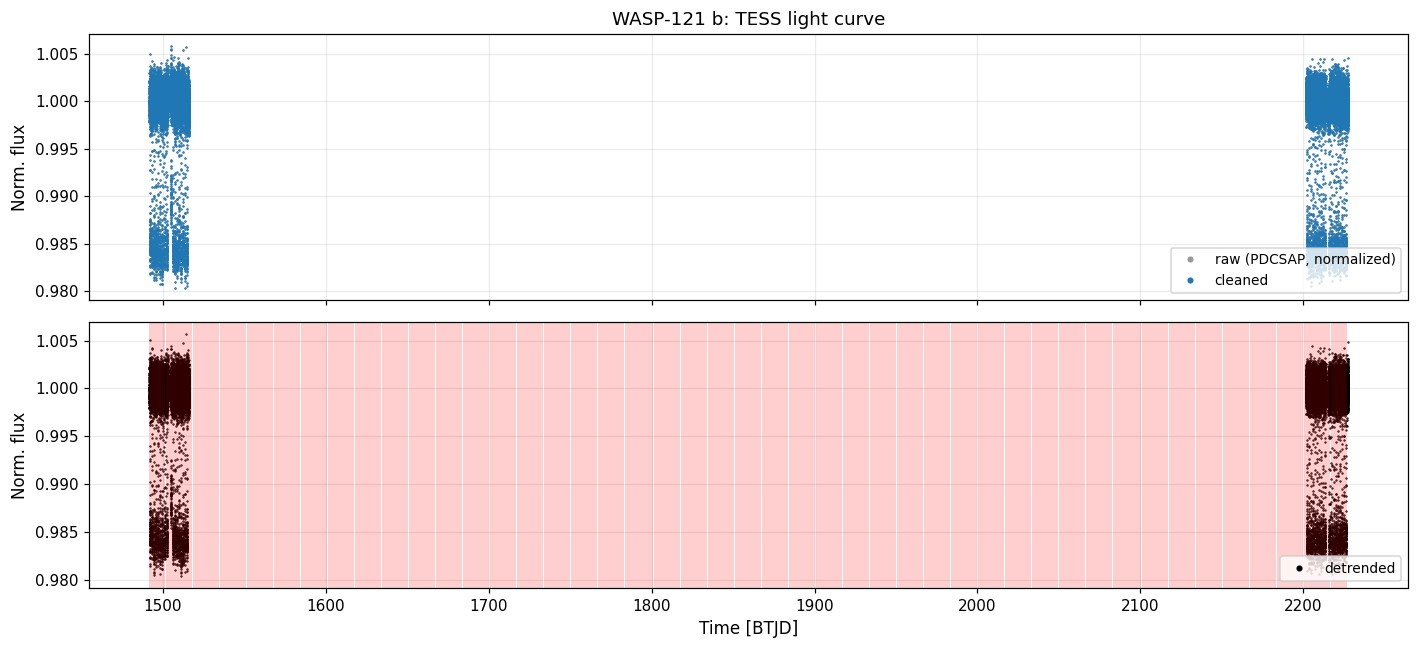

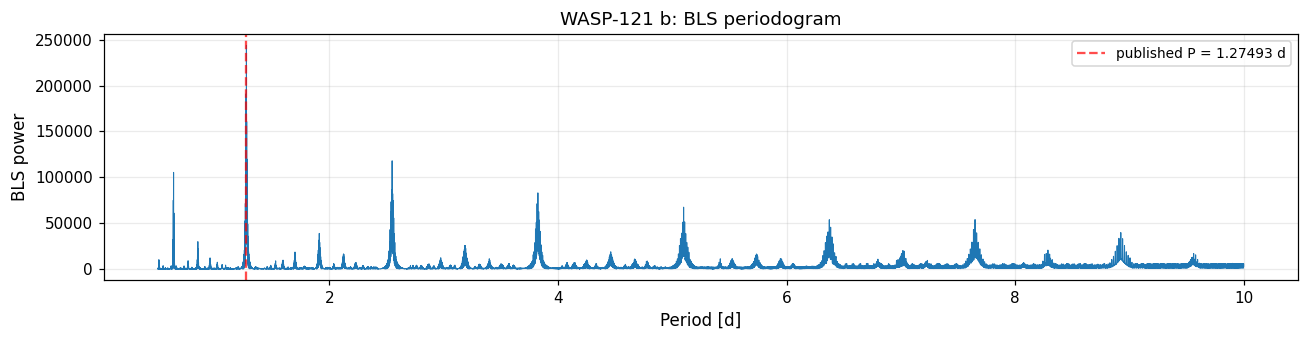

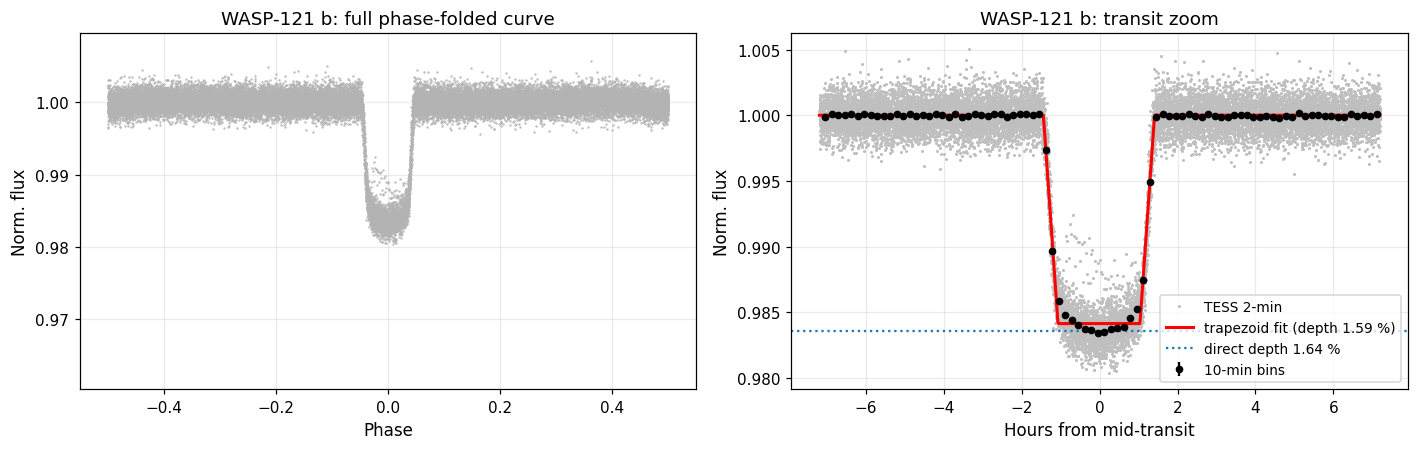

Planet               WASP-121 b
Sectors                       2
Transits seen                37
P_BLS [d]               1.27492
P_published [d]        1.274925
ΔP [s]                     -0.3
T14 [h]                    2.86
Depth direct [%]           1.64
Depth fit [%]             1.586
Rp/R* (fit)              0.1259
Rp/R* (±)                0.0001
Rp/R* (published)        0.1218
Diff [%]                    3.4


In [12]:
results, store = [], {}
for name, cfg in TARGETS.items():
    try:
        res, st = analyze_target(name, cfg)
        results.append(res); store[name] = st
    except Exception as e:
        print(f"{name} failed: {e}")

## 6. Summary table

In [13]:
summary = pd.DataFrame(results).set_index("Planet")
display(summary.T)

Planet,WASP-18 b,HD 209458 b,WASP-121 b
Sectors,2.000000,2.000000,2.000000
Transits seen,48.000000,15.000000,37.000000
P_BLS [d],0.941420,3.524750,1.274920
P_published [d],0.941452,3.524749,1.274925
ΔP [s],-3.200000,-0.000000,-0.300000
T14 [h],2.180000,3.000000,2.860000
Depth direct [%],1.090000,1.587000,1.640000
Depth fit [%],1.053000,1.542000,1.586000
Rp/R* (fit),0.102600,0.124200,0.125900
Rp/R* (±),0.000100,0.000100,0.000100


## 7. Comparison: all planets side by side

Because we normalized the time axis to hours from mid-transit, it is easy to compare the transit shapes. Deeper transit means larger Rp/R★.

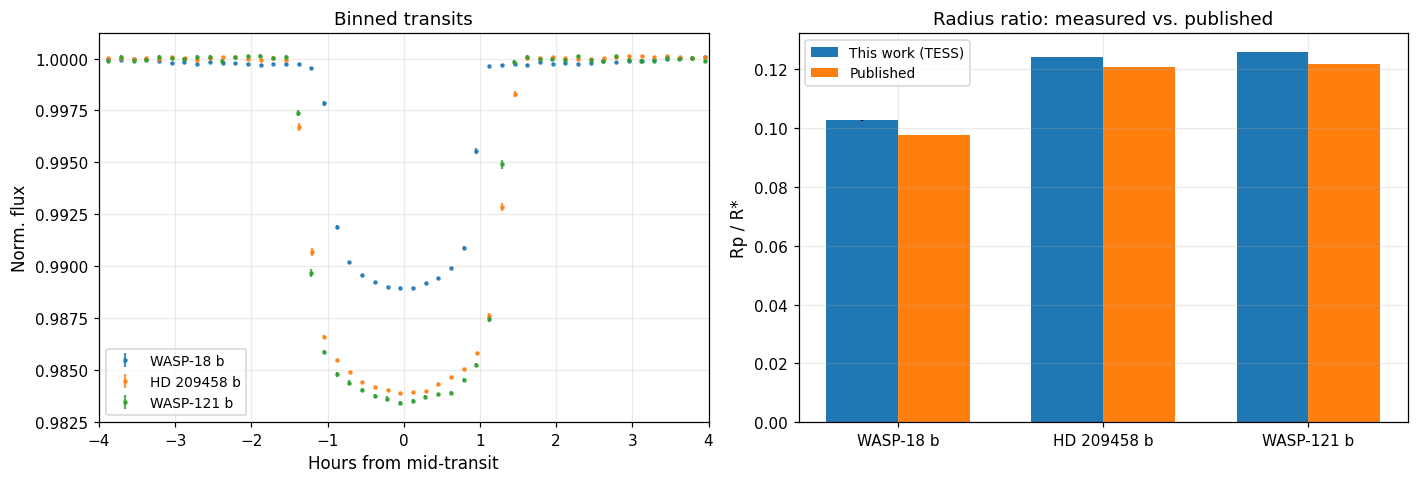

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

for name, (xb, yb, eb, popt) in store.items():
    ax[0].errorbar(xb, yb, eb, fmt=".", ms=4, alpha=0.8, label=name)
ax[0].set_xlim(-4, 4); ax[0].set_xlabel("Hours from mid-transit"); ax[0].set_ylabel("Norm. flux")
ax[0].set_title("Binned transits"); ax[0].legend()

x = np.arange(len(summary)); w = 0.35
ax[1].bar(x - w/2, summary["Rp/R* (fit)"], w, yerr=summary["Rp/R* (±)"], label="This work (TESS)")
ax[1].bar(x + w/2, summary["Rp/R* (published)"], w, label="Published")
ax[1].set_xticks(x); ax[1].set_xticklabels(summary.index)
ax[1].set_ylabel("Rp / R*"); ax[1].set_title("Radius ratio: measured vs. published"); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. Discussion

**Depth → radius ratio.** During a transit the planet blocks a fraction of the stellar disc equal to the ratio of the two projected areas:

$$\delta \approx \left(\frac{R_p}{R_\star}\right)^2 \quad\Longrightarrow\quad \frac{R_p}{R_\star}\approx\sqrt{\delta}$$

So a ~1 % deep transit means the planet has ~10 % of the star's radius. For a Sun-like star that is roughly a Jupiter-sized planet (Jupiter/Sun ≈ 0.1). All three targets are hot Jupiters, which is why they show up so clearly even in a few days of data.

**Period.** The blind BLS period agrees with the published value to within a few seconds up to a few tens of seconds. The precision is limited by how many transits we have and the timing noise. The published periods come from years of observations, so they are far more precise.

**Why our Rp/R★ may differ slightly from the published value:**

* **Limb darkening.** A star is brighter in the centre than at the edge. A planet crossing the centre blocks more light than its area fraction suggests, so √(depth) is typically a few % larger than the true Rp/R★. A proper transit model (e.g. `batman`) with limb-darkening coefficients would fix this.
* **Impact parameter.** A high-impact-parameter (grazing) transit has a shallower, more V-shaped dip, which biases the trapezoid depth.
* **Dilution.** TESS has large pixels (21″). Light from nearby stars slightly dilutes the transit; PDCSAP corrects for most of this.
* **Detrending.** An aggressive filter can reduce the depth; we reduced this risk by masking the transits in the second flattening pass.
* **Simple model.** A trapezoid is only an approximation to the true transit shape.
* **Ultra-hot Jupiters** (WASP-18 b, WASP-121 b) also have strong phase-curve and ellipsoidal variations, so the out-of-transit baseline is not perfectly flat.

**Data:** TESS mission, accessed via MAST (https://archive.stsci.edu). **Software:** Lightkurve, Astropy, NumPy, SciPy, Matplotlib, pandas.